# Hack Club "hour detectives" — EDA, валидация, тюнинг, блендинг

Ноутбук для локальной работы (Ryzen 7 / RTX 4050). Признаки и модели **импортируются из
`predict.py`**, поэтому всё, что мы проверяем здесь, ровно то же самое, что запустится на
сервере. Положите `train.csv` рядом с ноутбуком (или поменяйте `DATA_DIR`).

План:
1. Связь `hours_spent` ↔ `log_hours` и точная формула метрики
2. EDA: распределение таргета, пропуски, сильнейшие признаки, категории
3. Признаки + абляция (что реально помогает)
4. 10-fold StratifiedKFold по `hours_bucket`, OOF всех моделей
5. Feature importance
6. (опционально) Optuna для LightGBM
7. Блендинг (неотрицательные веса) и пост-процессинг
8. Анализ ошибок

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import root_mean_squared_log_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

DATA_DIR = "."                      # где лежит train.csv
sys.path.insert(0, os.path.abspath("."))  # predict.py лежит рядом
import predict as P

N_FOLDS = int(os.environ.get("N_FOLDS", 10))
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
print(train.shape)
for lib in ["lightgbm", "catboost", "xgboost", "optuna"]:
    try:
        print(lib, __import__(lib).__version__)
    except ImportError:
        print(lib, "— не установлен")

(4500, 73)
lightgbm 4.7.0
catboost 1.2.10
xgboost 3.4.1
optuna 5.1.0


## 1. Как связаны `hours_spent` и `log_hours`, и что считает метрика

`sklearn.metrics.root_mean_squared_log_error` = `sqrt(mean((log1p(y) - log1p(ŷ))²))`.
Проверяем, что такое `log_hours`.

In [2]:
h, lh = train["hours_spent"], train["log_hours"]
print("max |ln(h)    - log_hours| =", (np.log(h) - lh).abs().max().round(4))
print("max |log1p(h) - log_hours| =", (np.log1p(h) - lh).abs().max().round(4))
print("max |exp(log_hours) - h|   =", (np.exp(lh) - h).abs().max().round(4))
print(train.loc[(np.log(h) - lh).abs() > 0.05, ["hours_spent", "log_hours"]].head())

max |ln(h)    - log_hours| = 1.2538
max |log1p(h) - log_hours| = 3.6517
max |exp(log_hours) - h|   = 0.0715
     hours_spent  log_hours
9            0.3    -1.1394
32           0.8    -0.2877
172          0.2    -1.6607
629          0.3    -1.2730
666          0.6    -0.5858


**Вывод.** `log_hours = ln(hours)` **без +1**, и посчитан от неокруглённых часов
(`hours_spent` округлён до 0.1, поэтому на 0.1–0.8 ч расхождения заметны).
Метрика же работает с `log1p`. Поэтому:
* учим все модели на **`y = log1p(hours_spent)`** с RMSE-лоссом — тогда RMSE в этом
  пространстве *в точности* равен RMSLE;
* на инференсе `expm1` и клип в `[0.1, 140.7]` (реальный диапазон меток).

`log_hours` как таргет использовать не нужно: он смещён относительно метрики, особенно
на маленьких проектах.

In [3]:
y = np.log1p(train["hours_spent"].values)
const = np.full_like(y, y.mean())
print("Константа (mean log1p):", round(P.rmse(const, y), 4), " — в условии «about 0.97»")
print("Бакеты:", train["hours_bucket"].value_counts().to_dict())
print("Строк на потолке 140.7:", int((train.hours_spent >= 140.7).sum()))

Константа (mean log1p): 0.9623  — в условии «about 0.97»
Бакеты: {'<10': 2985, '10-30': 1120, '30-100': 332, '100+': 63}
Строк на потолке 140.7: 24


## 2. EDA

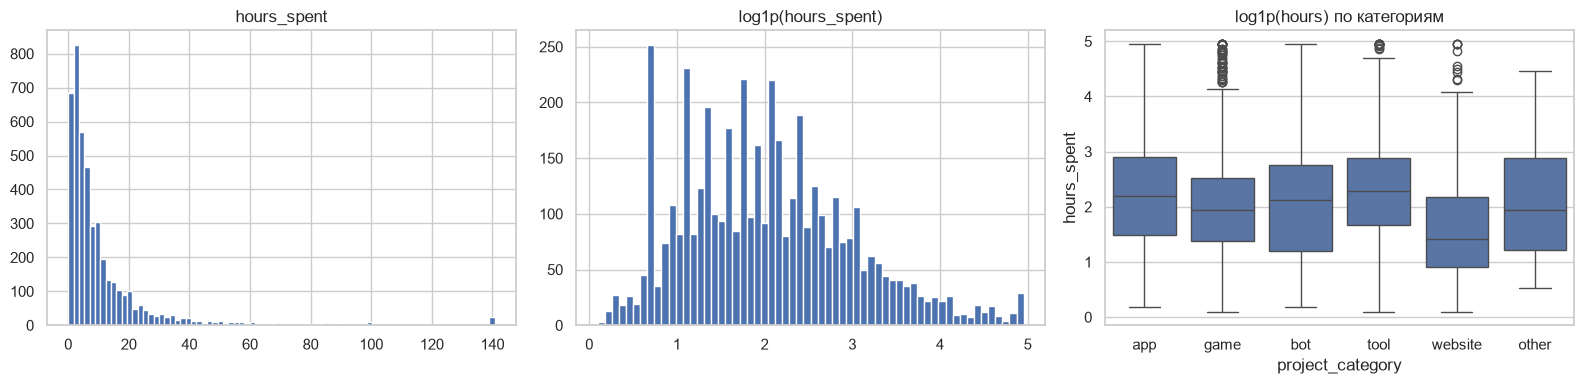

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(train.hours_spent, bins=80); ax[0].set_title("hours_spent")
ax[1].hist(y, bins=60); ax[1].set_title("log1p(hours_spent)")
sns.boxplot(data=train, x="project_category", y=np.log1p(train.hours_spent), ax=ax[2])
ax[2].set_title("log1p(hours) по категориям"); plt.tight_layout(); plt.show()

In [5]:
na = train.isna().mean().sort_values(ascending=False)
na = na[na > 0]
print(na.round(3).to_string())
# Несёт ли пропуск сигнал?
for c in ["page_weight_kb", "num_js_files_loaded", "pct_code_in_first_commit", "pct_primary_language"]:
    m = train[c].isna()
    print(f"{c:28s} missing: mean log1p y = {y[m].mean():.3f}  vs present {y[~m].mean():.3f}  (n={m.sum()})")

is_mobile_responsive        0.316
num_js_files_loaded         0.316
num_internal_pages          0.316
page_weight_kb              0.300
load_time_ms                0.300
comment_line_ratio          0.043
avg_file_length             0.043
pct_primary_language        0.043
pct_code_in_first_commit    0.041
churn_ratio                 0.005
project_category            0.001
is_clone_or_tutorial        0.001
is_multiplayer              0.001
mentions_ai_api             0.001
has_custom_art              0.000
page_weight_kb               missing: mean log1p y = 2.334  vs present 1.911  (n=1349)
num_js_files_loaded          missing: mean log1p y = 2.319  vs present 1.908  (n=1423)
pct_code_in_first_commit     missing: mean log1p y = 1.642  vs present 2.055  (n=186)
pct_primary_language         missing: mean log1p y = 1.638  vs present 2.056  (n=194)


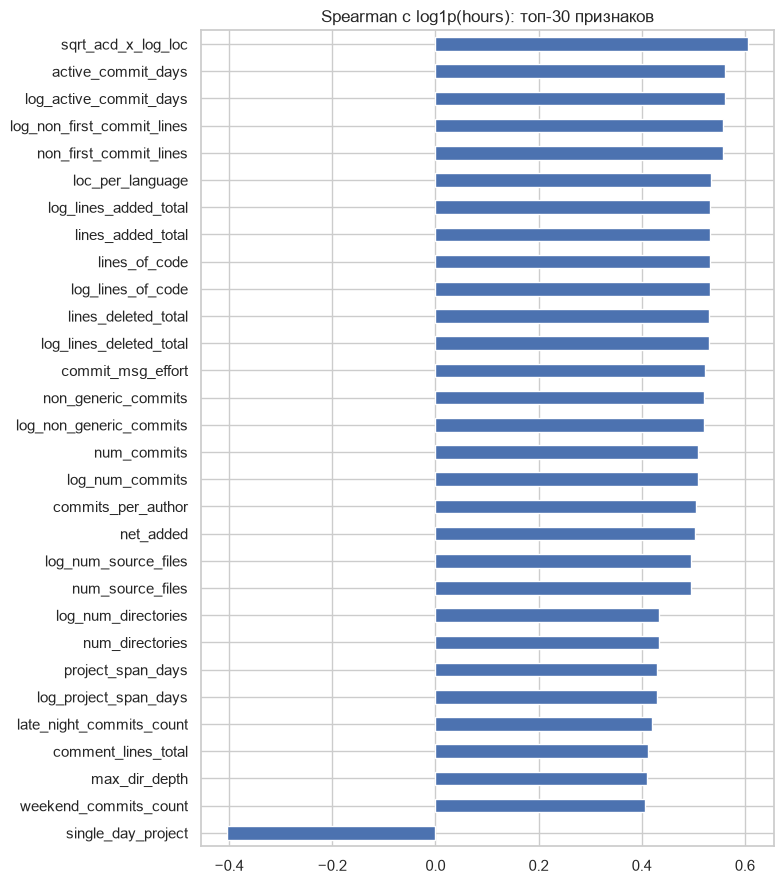

In [6]:
Xtr, _, cats = P.build_features(train, train.drop(columns=P.LABELS).iloc[:0])
num = [c for c in Xtr.columns if c not in cats]
corr = Xtr[num].corrwith(pd.Series(y), method="spearman").dropna()
top = corr.abs().sort_values(ascending=False).head(30).index
plt.figure(figsize=(8, 9))
corr[top].sort_values().plot.barh()
plt.title("Spearman с log1p(hours): топ-30 признаков"); plt.tight_layout(); plt.show()

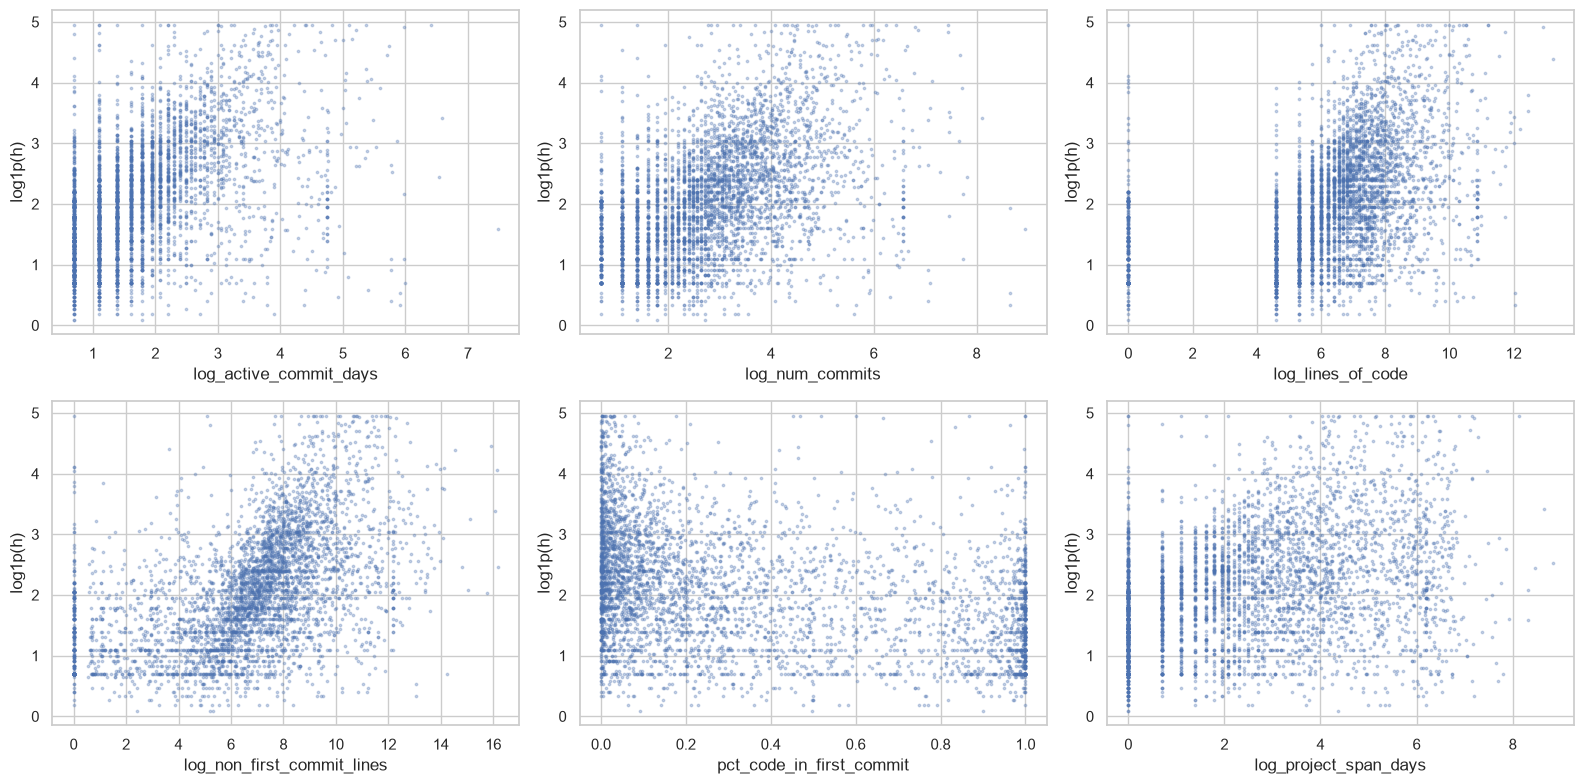

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for a, c in zip(axes.ravel(), ["log_active_commit_days", "log_num_commits", "log_lines_of_code",
                               "log_non_first_commit_lines", "pct_code_in_first_commit", "log_project_span_days"]):
    a.scatter(Xtr[c], y, s=3, alpha=0.3); a.set_xlabel(c); a.set_ylabel("log1p(h)")
plt.tight_layout(); plt.show()

In [8]:
for c in ["author_prior_projects", "commit_cadence", "framework", "hosting_type", "is_clone_or_tutorial"]:
    print(train.assign(ly=y).groupby(c, dropna=False)["ly"].agg(["mean", "count"]).sort_values("count", ascending=False).head(10).round(3), "\n")

                        mean  count
author_prior_projects              
0                      1.947   1959
1-2                    2.122   1037
6+                     2.116    826
3-5                    2.078    678 

                 mean  count
commit_cadence              
frequent        1.842   2561
sporadic        2.198    992
daily           2.399    947 

            mean  count
framework              
none       1.881   2472
godot      2.178    658
nextjs     2.297    195
other      2.429    194
react      2.205    189
unity      2.410     97
gamemaker  1.576     83
astro      2.231     82
flask      2.274     81
sveltekit  2.312     75 

                   mean  count
hosting_type                  
itch              1.953   1088
github-pages      1.675   1032
custom            2.329    689
github-repo       2.381    509
vercel            2.021    377
hack-club         2.153    215
netlify           1.769    116
video             2.567     85
other             2.282     82
pack

## 3. Валидация и абляция признаков

10-fold `StratifiedKFold` по `hours_bucket`. Для быстрой абляции используем HistGB (есть
везде). Сравниваем: только сырые колонки / + инженерные / + групповые агрегаты.

In [9]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import HistGradientBoostingRegressor

folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=P.SEED)
             .split(train, train["hours_bucket"]))
vocab = {c: sorted(Xtr[c].astype(str).unique()) for c in cats}

def cv_hgb(X, seed=0):
    Xc = P.to_codes_fixed(X, [c for c in cats if c in X], vocab)
    oof = np.zeros(len(y))
    for a, b in folds:
        m = HistGradientBoostingRegressor(learning_rate=0.03, max_iter=900, max_leaf_nodes=20,
                                          min_samples_leaf=25, l2_regularization=3, max_features=0.5,
                                          categorical_features=[c in cats for c in Xc.columns], random_state=seed)
        m.fit(Xc.iloc[a], y[a]); oof[b] = m.predict(Xc.iloc[b])
    return P.rmse(oof, y)

raw = [c for c in train.columns if c not in P.LABELS + ["project_id"]]
raw_feats = [c for c in Xtr.columns if c in raw or c.replace("_cat", "") in raw]
P.USE_GROUP_AGGS = True
Xg, _, _ = P.build_features(train, train.drop(columns=P.LABELS).iloc[:0])
P.USE_GROUP_AGGS = False
ablation = {
    "raw only": cv_hgb(Xtr[raw_feats]),
    "raw + engineered (prod)": cv_hgb(Xtr),
    "+ group aggregates": cv_hgb(Xg),
}
print(pd.Series(ablation).round(4))

raw only                   0.6669
raw + engineered (prod)    0.6648
+ group aggregates         0.6666
dtype: float64


В нашем прогоне (5 фолдов) разница была ~0.002 — в пределах шума: деревья сами находят
отношения вроде `loc / commits`. Групповые агрегаты по train+test не помогли, поэтому в
`predict.py` они выключены (`USE_GROUP_AGGS = False`). Инженерные признаки оставляем: они
заметно помогают Ridge и ExtraTrees и добавляют разнообразия ансамблю.

**Стекинг с OOF-вероятностями `hours_bucket`** мы тоже проверили: стало хуже (0.690 против 0.669).
Бакеты — это просто огрублённый таргет, новой информации классификатор не несёт.
Проверка ниже.

In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier
Xc = P.to_codes_fixed(Xtr, cats, vocab)
yb = train.hours_bucket.map({b: i for i, b in enumerate(P.BUCKETS)}).values
proba = np.zeros((len(y), 4))
for a, b in folds:
    clf = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=20,
                                         categorical_features=[c in cats for c in Xc.columns], random_state=0)
    proba[b] = clf.fit(Xc.iloc[a], yb[a]).predict_proba(Xc.iloc[b])
Xs = Xtr.copy(); Xs[[f"pb{i}" for i in range(4)]] = proba
print("с вероятностями бакетов:", round(cv_hgb(Xs), 4))

с вероятностями бакетов: 0.6797


## 4. OOF всех моделей ансамбля (точно те же, что в predict.py)

In [11]:
models = P.make_models(cats, vocab)
oof = {}
for name, fn in models:
    t = time.time(); o = np.zeros(len(y))
    for a, b in folds:
        o[b] = fn(Xtr.iloc[a], y[a], Xtr.iloc[b])
    oof[name] = o
    print(f"{name:10s} OOF RMSLE {P.rmse(o, y):.4f}  ({time.time()-t:.0f}s)")
OOF = pd.DataFrame(oof)
print(OOF.corr().round(3))

lgbm       OOF RMSLE 0.6626  (51s)
catboost   OOF RMSLE 0.6615  (1040s)
xgboost    OOF RMSLE 0.6611  (69s)
hgb        OOF RMSLE 0.6643  (44s)
extratrees OOF RMSLE 0.6640  (43s)
ridge      OOF RMSLE 0.6898  (9s)
             lgbm  catboost  xgboost    hgb  extratrees  ridge
lgbm        1.000     0.980    0.989  0.988       0.956  0.919
catboost    0.980     1.000    0.986  0.977       0.964  0.925
xgboost     0.989     0.986    1.000  0.985       0.965  0.923
hgb         0.988     0.977    0.985  1.000       0.953  0.918
extratrees  0.956     0.964    0.965  0.953       1.000  0.923
ridge       0.919     0.925    0.923  0.918       0.923  1.000


## 5. Feature importance

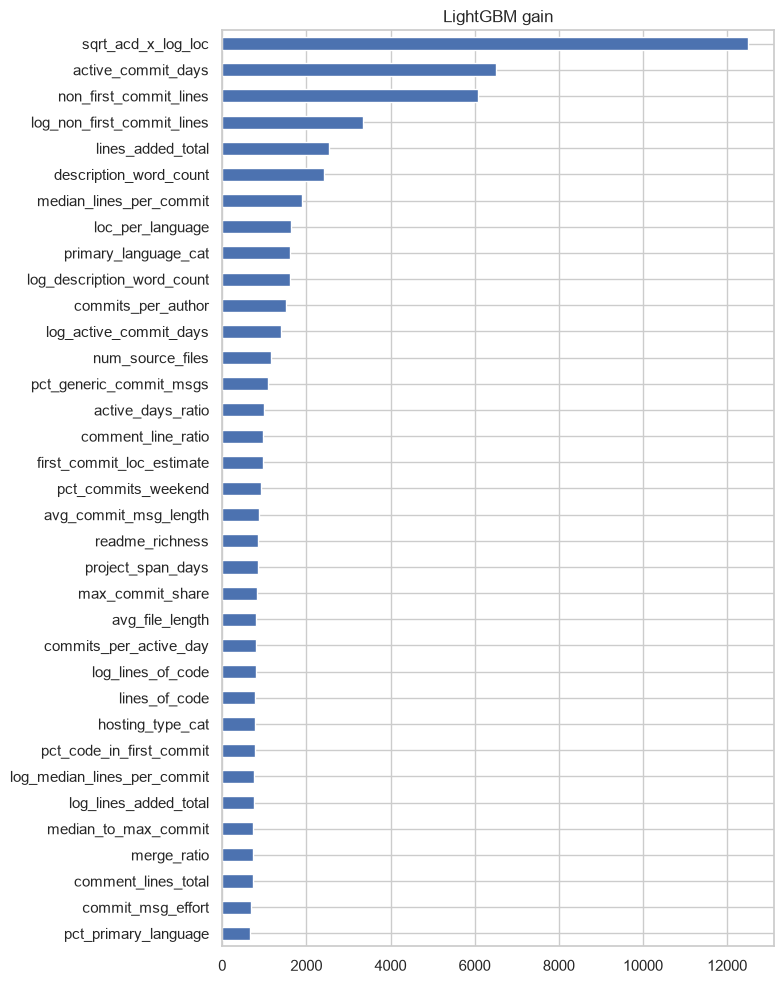

In [12]:
try:
    import lightgbm as lgb
    m = lgb.LGBMRegressor(learning_rate=0.02, n_estimators=1400, num_leaves=24, min_child_samples=25,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_alpha=0.5,
                          reg_lambda=3, importance_type="gain", verbose=-1, random_state=0)
    m.fit(Xc, y, categorical_feature=cats)
    imp = pd.Series(m.feature_importances_, Xc.columns)
    title = "LightGBM gain"
except ImportError:
    from sklearn.inspection import permutation_importance
    a, b = folds[0]
    m = HistGradientBoostingRegressor(learning_rate=0.03, max_iter=600, max_leaf_nodes=20,
                                      min_samples_leaf=25, categorical_features=[c in cats for c in Xc.columns],
                                      random_state=0).fit(Xc.iloc[a], y[a])
    r = permutation_importance(m, Xc.iloc[b], y[b], n_repeats=3, random_state=0,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)
    imp = pd.Series(r.importances_mean, Xc.columns)
    title = "Permutation importance (HistGB, fold 0)"
plt.figure(figsize=(8, 10)); imp.sort_values().tail(35).plot.barh(); plt.title(title); plt.tight_layout(); plt.show()

## 6. (опционально) Optuna для LightGBM

`pip install optuna`. ~50–100 trials занимают 10–30 минут на Ryzen 7. Лучшие параметры
вручную перенесите в `fit_lgb` в `predict.py` и перепроверьте OOF. Не перетюнивайте:
разница < 0.003 на 4.5k строках — это шум, смотрите на std по фолдам.

In [13]:
RUN_OPTUNA = False
if RUN_OPTUNA:
    import optuna, lightgbm as lgb

    def objective(trial):
        params = dict(
            objective="regression", n_estimators=3000, learning_rate=0.02, verbose=-1, random_state=0,
            num_leaves=trial.suggest_int("num_leaves", 8, 64, log=True),
            min_child_samples=trial.suggest_int("min_child_samples", 10, 80),
            subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.2, 0.9),
            reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
            min_split_gain=trial.suggest_float("min_split_gain", 0, 0.2))
        o = np.zeros(len(y)); iters = []
        for a, b in folds[:5]:
            m = lgb.LGBMRegressor(**params)
            m.fit(Xc.iloc[a], y[a], eval_set=[(Xc.iloc[b], y[b])], categorical_feature=cats,
                  callbacks=[lgb.early_stopping(150, verbose=False)])
            o[b] = m.predict(Xc.iloc[b]); iters.append(m.best_iteration_)
        trial.set_user_attr("n_estimators", int(np.mean(iters)))
        idx = np.concatenate([b for _, b in folds[:5]])
        return P.rmse(o[idx], y[idx])

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0))
    study.optimize(objective, n_trials=80, show_progress_bar=True)
    print(study.best_value, study.best_params, study.best_trial.user_attrs)

## 7. Блендинг и пост-процессинг

In [14]:
names = list(OOF.columns)
w = P.nnls_weights(OOF.values, y)
blend = OOF.values @ w
print("weights:", dict(zip(names, w.round(3))))
print("blend OOF RMSLE:", round(P.rmse(blend, y), 4))
per_fold = [P.rmse(blend[b], y[b]) for _, b in folds]
print("по фолдам: mean %.4f  std %.4f" % (np.mean(per_fold), np.std(per_fold)))

# Альтернатива — Ridge-стекинг с положительными коэффициентами и свободным intercept
from sklearn.linear_model import LinearRegression
st = np.zeros(len(y))
for a, b in folds:
    st[b] = LinearRegression(positive=True).fit(OOF.values[a], y[a]).predict(OOF.values[b])
print("positive-LR stack OOF:", round(P.rmse(st, y), 4))

weights: {'lgbm': np.float64(0.21), 'catboost': np.float64(0.154), 'xgboost': np.float64(0.0), 'hgb': np.float64(0.178), 'extratrees': np.float64(0.341), 'ridge': np.float64(0.117)}
blend OOF RMSLE: 0.6526
по фолдам: mean 0.6522  std 0.0234
positive-LR stack OOF: 0.6529


In [15]:
# Пост-процессинг: сдвиг, растяжение вокруг среднего, клип (всё в log1p-пространстве)
def score(pl):
    return root_mean_squared_log_error(train.hours_spent, np.clip(np.expm1(pl), 0.1, 140.7))
print("blend + clip:", round(score(blend), 4))
for s in [-0.05, -0.02, 0, 0.02, 0.05]:
    print(f"shift {s:+.2f}: {score(blend + s):.4f}")
mu = blend.mean()
for k in [0.95, 1.0, 1.05, 1.1, 1.15]:
    print(f"stretch {k:.2f}: {score(mu + k*(blend-mu)):.4f}")
for lo in [0.1, 0.5, 1.0]:
    print(f"clip lo {lo}: {root_mean_squared_log_error(train.hours_spent, np.clip(np.expm1(blend), lo, 140.7)):.4f}")

blend + clip: 0.6526
shift -0.05: 0.6548
shift -0.02: 0.6531
shift +0.00: 0.6526
shift +0.02: 0.6528
shift +0.05: 0.6543
stretch 0.95: 0.6548
stretch 1.00: 0.6526
stretch 1.05: 0.6522
stretch 1.10: 0.6536
stretch 1.15: 0.6567
clip lo 0.1: 0.6526
clip lo 0.5: 0.6526
clip lo 1.0: 0.6526


Если растяжение `k > 1` даёт стабильный выигрыш по фолдам (а не только на всём OOF), его можно
добавить в `predict.py`. Деревья с RMSE-лоссом «поджимают» прогнозы к среднему, и небольшое
растяжение иногда помогает. Проверяйте на фолдах, а не на одном числе.

## 8. Анализ ошибок

               mean   rmse  count
hours_bucket                     
10-30        -0.305  0.568   1120
100+         -1.614  1.705     63
30-100       -0.906  1.054    332
<10           0.244  0.580   2985


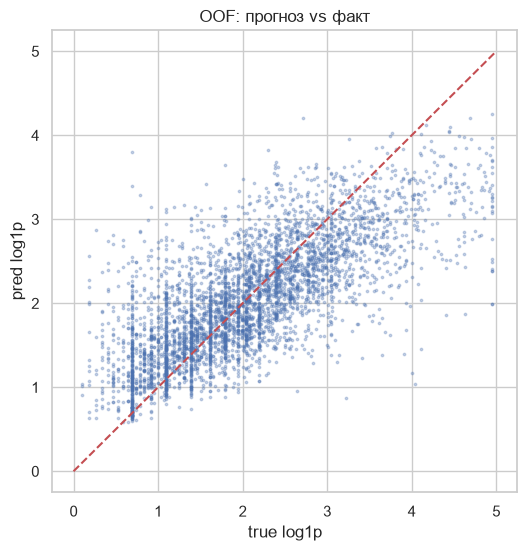

      hours_spent       pred  num_commits  active_commit_days  lines_of_code  \
1779          1.0  43.565398           62                  35          18100   
1245         56.0   1.817587            1                   1              0   
3372        140.7   6.295171           18                   8              0   
248         140.7   6.353430            1                   1          37400   
8            53.5   2.204197           27                   3              0   
1557        101.2   5.530670           12                   2            400   
2850          1.0  28.880332         1214                 400          14700   
2793         60.0   3.311555            4                   3              0   
9             0.3  16.584891           21                  11           1900   
2505        140.7   9.833653          171                  89           3100   

     project_category  
1779             game  
1245          website  
3372             tool  
248              game  

In [16]:
res = blend - y
df_err = train.assign(pred=np.expm1(blend), res=res)
print(df_err.groupby("hours_bucket")["res"].agg(["mean", lambda r: np.sqrt(np.mean(r**2)), "count"])
      .rename(columns={"<lambda_0>": "rmse"}).round(3))
plt.figure(figsize=(6, 6))
plt.scatter(y, blend, s=3, alpha=0.3); plt.plot([0, 5], [0, 5], "r--")
plt.xlabel("true log1p"); plt.ylabel("pred log1p"); plt.title("OOF: прогноз vs факт"); plt.show()
print(df_err.loc[res.abs().sort_values(ascending=False).index[:10] if isinstance(res, pd.Series) else np.argsort(-np.abs(res))[:10],
             ["hours_spent", "pred", "num_commits", "active_commit_days", "lines_of_code", "project_category"]])

**Типичная картина:** модель переоценивает очень маленькие проекты (0.1–1 ч) и недооценивает
100+ — регрессия к среднему. Часть проектов с одинаковыми метаданными получила очень разные
часы от ревьюеров: это неустранимый шум, и он задаёт потолок ~0.65 RMSLE.

## 9. Финальная проверка `predict.py`
Симуляция боевого запуска: отложите 500 строк, удалите метки, положите `train.csv`/`test.csv`
в отдельную папку вместе с `predict.py`, запустите `python predict.py` и посчитайте RMSLE.